# 04 · Module 3: reliability-weighted fusion (3A) and waveform-conditioned fusion (3B)

**Module 3A.** Stability-weighted maps from Module 2 are fused with a geometric mean, computed over perturbations accepted by **both** branches:
$$R(u)=\sqrt{H_{1D}(u)\,H_{2D}(u)},\qquad H_b=\mu_b S_b .$$
Two fused baselines use the same geometric mean without stability: the anchor-style fusion of the raw Grad-CAM maps, $F_{\mathrm{base}}=\sqrt{B_1B_2}$,
and the fusion of perturbation means, $F_{\mu}=\sqrt{\mu_1\mu_2}$ (defined only for the 551 recordings where all 30 perturbations were accepted by both branches).

**Module 3B.** $R$ is additionally weighted by how much of the 2D Grad-CAM lies on the rendered waveform,
$$F_{\mathrm{trace}}(u)=\frac{\sum_y H(y,u)M(y,u)}{\sum_y H(y,u)+\varepsilon},\qquad R_{\mathrm{trace}}(u)=R(u)\,F_{\mathrm{trace}}(u)^{\lambda},\ \lambda\in\{0.5,1,2\},$$
with $M$ the trace mask dilated by ±6 px. Since $0\le F_{\mathrm{trace}}\le1$, $R_{\mathrm{trace}}\le R$ by construction.

The maps were produced on the HPC (`src/hpc_pipeline/04_module3_fusion_faithfulness/`: `m3a_prepare.py`, `m3b_generate_trace_support.py`, `m3b_apply.py`).
This notebook audits them, recomputes the fusion formulas and summarises the cohort. Faithfulness is evaluated in notebook 05.

> **Code on GitHub.** The re-run of the MM-GradCAM anchor (cohort, frozen split, 1D/2D CNN training and test-split manifests) is on the `main` branch of <https://github.com/dwiharyani/dan-mmgradcam-anchor-replication>. The Grad-CAM temporal alignment and the Module 1 alignment code are on the `module1-nahida` branch of the same repository. The same scripts are also included in `src/hpc_pipeline/` of the submitted package.

> **Google Colab:** upload `DAN-MMGradCAM_COE691.zip` (Files panel), then run `!unzip -q DAN-MMGradCAM_COE691.zip -d /content` once in a code cell. The setup cell below finds the folder automatically. **Jupyter:** open this notebook from the `notebooks/` folder of the extracted package.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

def find_root():
    """Repository root: works from notebooks/, from the root itself, and in Google Colab (/content)."""
    here = Path.cwd().resolve()
    for p in [here, *here.parents, Path('/content/DAN-MMGradCAM'), Path('/content/drive/MyDrive/DAN-MMGradCAM')]:
        if (p / 'data' / 'archived').is_dir() and (p / 'src').is_dir():
            return p
    raise FileNotFoundError('DAN-MMGradCAM folder not found. In Colab, upload DAN-MMGradCAM_COE691.zip and run: '
                            '!unzip -q DAN-MMGradCAM_COE691.zip -d /content')
ROOT = find_root()                          # repository root
sys.path.insert(0, str(ROOT / 'src'))
ARCH = ROOT / 'data' / 'archived'           # archived HPC outputs (inputs of this notebook)
TAB = ROOT / 'results' / 'tables'           # tables written by the notebooks
FIG = ROOT / 'results' / 'figures'          # figures written by the notebooks (used in the report)
TAB.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40); pd.set_option('display.precision', 4)
warnings.filterwarnings('ignore', category=RuntimeWarning)
CLASSES = ['AFib', 'GSVT', 'SB', 'SR']
def show(name, width=900):
    """Display a figure that a plotting function saved to results/figures."""
    display(Image(filename=str(FIG / f'{name}.png'), width=width))
print('repository root:', ROOT.name)

repository root: DAN-MMGradCAM


## 1. Module 3A eligibility and formula check

In [2]:
s3a = json.loads((ARCH / 'module3a/module3a_summary.json').read_text())
el = pd.read_csv(ARCH / 'module3a/module3a_eligible_records.csv')
z3 = np.load(ARCH / 'module3a/module3a_maps.npz')
flow = pd.DataFrame({'step': ['Module 2 records', 'frozen Module 1 primary recordings',
                              'eligible for Module 3A (both correct in Module 2, >= 2 joint acceptances, masks and labels match)',
                              'all 30 perturbations jointly accepted (matched-30, used for F_mu)'],
                     'n': [s3a['n_module2'], s3a['n_module1_frozen_primary'], s3a['n_primary_eligible_m2'], s3a['n_primary_matched30_clean']]})
display(flow)
V = z3['valid_600'].astype(bool)
err_R = max(np.abs(z3['R'][i][V[i]] - np.sqrt(np.clip(z3['H1j'][i][V[i]], 0, None) * np.clip(z3['H2j'][i][V[i]], 0, None))).max()
            for i in range(len(V)))
err_F = max(np.abs(z3['Fbase'][i][V[i]] - np.sqrt(np.clip(z3['base1'][i][V[i]], 0, None) * np.clip(z3['base2'][i][V[i]], 0, None))).max()
            for i in range(len(V)))
print(f'max |R - sqrt(H1 H2)| recomputed here: {err_R:.2e}   (HPC audit: {s3a["max_R_formula_error"]:.2e})')
print(f'max |F_base - sqrt(B1 B2)| recomputed here: {err_F:.2e}')
print('median mean R over eligible recordings:', round(s3a['median_r_mean_eligible'], 4),
      '| median intensity ratio R / F_mu (matched-30):', round(s3a['median_matched30_ratio_r_over_mu'], 4))

,step,n
0,Module 2 records,1054
1,frozen Module 1 primary recordings,727
2,eligible for Module 3A (both correct in Module...,694
3,all 30 perturbations jointly accepted (matched...,551


max |R - sqrt(H1 H2)| recomputed here: 0.00e+00   (HPC audit: 3.32e-08)
max |F_base - sqrt(B1 B2)| recomputed here: 0.00e+00
median mean R over eligible recordings: 0.0775 | median intensity ratio R / F_mu (matched-30): 0.4975


In [3]:
by_cls = el.groupby('class_name').agg(n=('cohort_index', 'size'), matched30=('full_joint_30', 'sum'),
                                     median_R_mean=('r_mean', 'median'), median_R_over_Fmu=('r_fmu_intensity_ratio', 'median'),
                                     median_shape_r_R_vs_Fmu=('r_fmu_shape_pearson', 'median'))
by_cls.loc['All'] = [len(el), el.full_joint_30.sum(), el.r_mean.median(), el.r_fmu_intensity_ratio.median(), el.r_fmu_shape_pearson.median()]
by_cls.to_csv(TAB / 'module3A_by_class.csv'); by_cls.round(3)

,n,matched30,median_R_mean,median_R_over_Fmu,median_shape_r_R_vs_Fmu
class_name,,,,,
AFib,182.0,165.0,0.074,0.505,0.856
GSVT,185.0,138.0,0.087,0.513,0.856
SB,200.0,153.0,0.067,0.480,0.875
SR,127.0,95.0,0.086,0.473,0.852
All,694.0,551.0,0.078,0.498,0.859


## 2. What stability weighting changes

In [4]:
def topk(x, f=.10):
    k = int(np.ceil(f * x.size)); s = np.zeros(x.size, bool); s[np.argsort(-x, kind='stable')[:k]] = True; return s
def iou(a, b): return (a & b).sum() / (a | b).sum()
def ent(x):
    p = np.clip(x, 0, None); p = p / p.sum(); nz = p[p > 0]; return float(-(nz * np.log(nz)).sum() / np.log(p.size))
z2 = np.load(ARCH / 'module2/noise_stability_maps.npz'); rec = pd.read_csv(ARCH / 'module2/noise_stability_records.csv')
bc = ((rec.pred_1d == rec.class_name) & (rec.pred_2d == rec.class_name)).to_numpy(); v = z2['valid_600'][0].astype(bool)
rows = []
for i in np.flatnonzero(bc):
    H1, H2, R, mu1, mu2 = (z2[k][i][v] for k in ('H1', 'H2', 'R', 'mu1', 'mu2'))
    R0 = np.sqrt(np.clip(mu1, 0, None) * np.clip(mu2, 0, None))
    rows.append({'cohort_index': rec.cohort_index[i], 'class_name': rec.class_name[i],
                 'IoU10(R, H1D)': iou(topk(R), topk(H1)), 'IoU10(R, H2D)': iou(topk(R), topk(H2)),
                 'IoU10(R, no-stability fusion)': iou(topk(R), topk(R0)), 'mass kept by R vs no-stability': R.sum() / R0.sum(),
                 'entropy H1D': ent(H1), 'entropy H2D': ent(H2), 'entropy R': ent(R)})
loc = pd.DataFrame(rows); loc.to_csv(TAB / 'module3A_location_per_record.csv', index=False)
q = loc.drop(columns=['cohort_index', 'class_name']).quantile([.25, .5, .75]).T
q.columns = ['Q1', 'median', 'Q3']; q.round(3)

,Q1,median,Q3
"IoU10(R, H1D)",0.317,0.385,0.479
"IoU10(R, H2D)",0.137,0.200,0.286
"IoU10(R, no-stability fusion)",0.367,0.440,0.521
mass kept by R vs no-stability,0.461,0.500,0.534
entropy H1D,0.887,0.909,0.928
entropy H2D,0.958,0.968,0.976
entropy R,0.926,0.943,0.956


**Reading.** The top-10 % columns of $R$ coincide much more with those of $H_{1D}$ than with those of $H_{2D}$: the broad, flat 2D map mainly scales the 1D map,
and removes 1D peaks where the 2D map is weak or unstable.

saved fig_module3A_case209
saved col_module3A


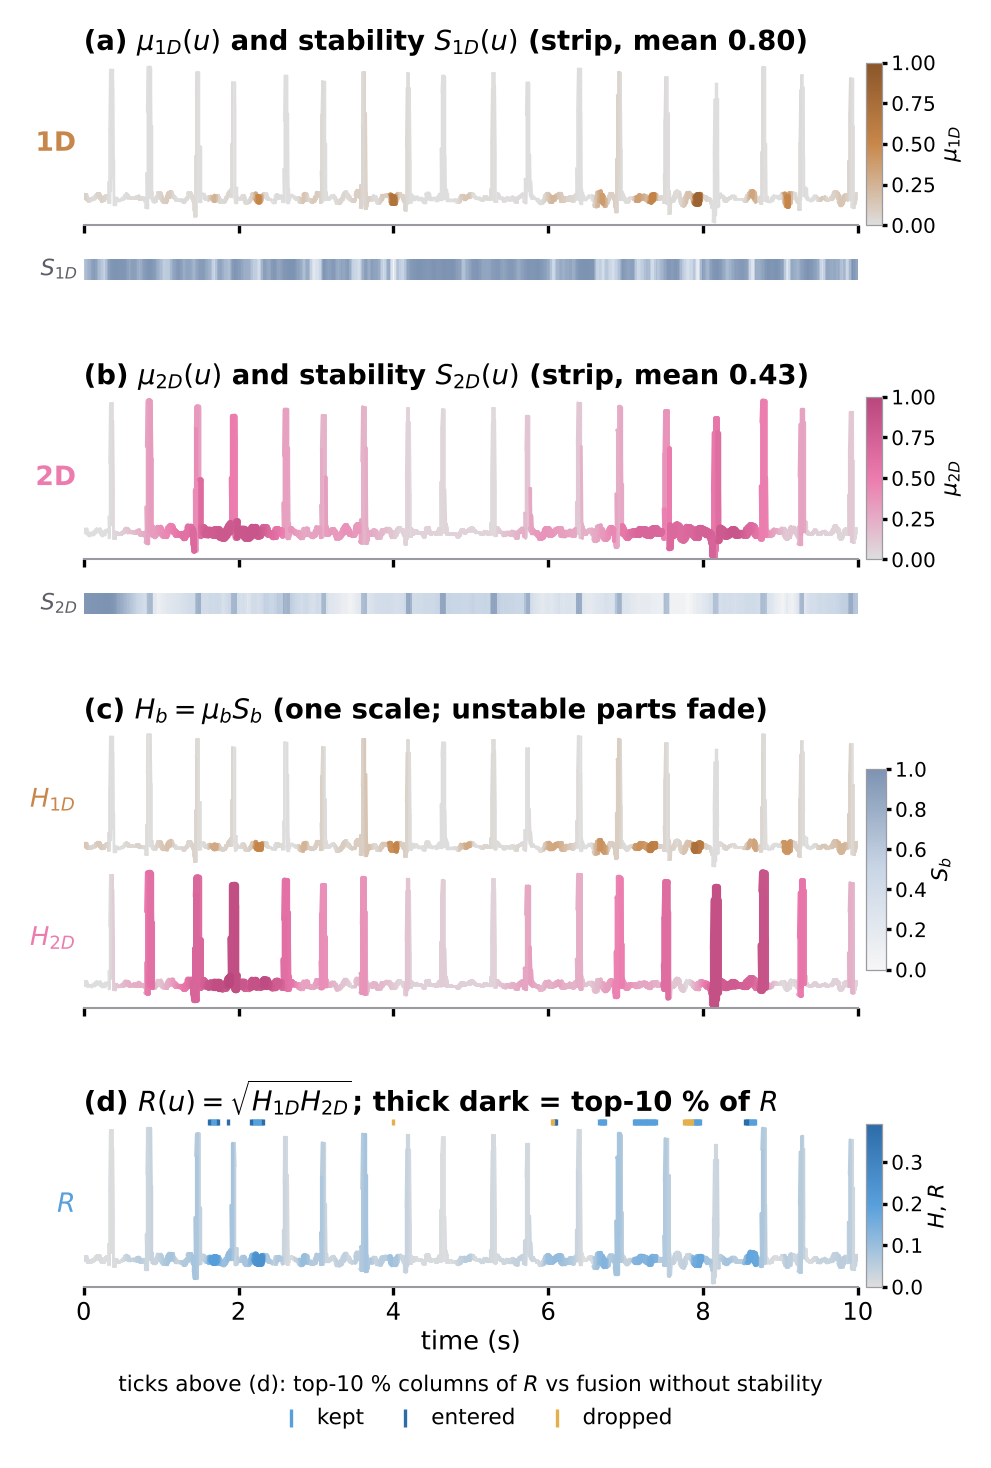

In [5]:
import dan_figures as F
mask = np.load(ARCH / 'module1/ecg209_trace_mask.npy')
i209 = int(np.flatnonzero(z2['cohort_index'] == 209)[0])
import dan_column_figures as C
F.fig_case_module3a(z2, i209, mask, FIG)
C.fig_module3a_column(z2, i209, mask, FIG)        # single-column version used in the report
show('col_module3A', 420)

## 3. Module 3B: waveform conditioning

In [6]:
z3b = np.load(ARCH / 'module3b/module3b_maps.npz')
m3b = pd.read_csv(ARCH / 'module3b/module3b_record_metrics.csv')
V3 = z3b['valid_600'].astype(bool)
err = 0.0
for lam, key in ((0.5, 'Rtrace_lambda_0p5'), (1.0, 'Rtrace_lambda_1p0'), (2.0, 'Rtrace_lambda_2p0')):
    for i in range(len(V3)):
        v_ = V3[i]; err = max(err, np.abs(z3b[key][i][v_] - z3b['R'][i][v_] * np.clip(z3b['F_trace'][i][v_], 0, None) ** lam).max())
print('records:', len(V3), '| max |R_trace - R F_trace^lambda| recomputed here: %.2e' % err)
print('R_trace <= R everywhere:', all((z3b[k][V3] <= z3b['R'][V3] + 1e-7).all() for k in ('Rtrace_lambda_0p5', 'Rtrace_lambda_1p0', 'Rtrace_lambda_2p0')))
def iqr(s): return '%.3f (%.3f–%.3f)' % (s.median(), s.quantile(.25), s.quantile(.75))
coh = m3b.groupby('lambda').agg(n=('cohort_index', 'size'), mass_kept_vs_R=('Rtrace_over_R_mean', iqr),
                                top10_IoU_vs_R=('top10_IoU', iqr), shape_Pearson_vs_R=('shape_Pearson', iqr))
sens = pd.read_csv(ARCH / 'module3b_sensitivity/module3b_record_metrics.csv')
coh['mass kept, sensitivity run (694, median)'] = sens.groupby('lambda').Rtrace_over_R_mean.median().round(4)
coh.to_csv(TAB / 'module3B_cohort.csv')
on_trace = m3b.drop_duplicates('cohort_index').F_trace_mean
print('median on-trace share of the 2D Grad-CAM per recording: %.3f (IQR %.3f–%.3f)' % (on_trace.median(), on_trace.quantile(.25), on_trace.quantile(.75)))
coh

records: 693 | max |R_trace - R F_trace^lambda| recomputed here: 2.98e-08
R_trace <= R everywhere: True
median on-trace share of the 2D Grad-CAM per recording: 0.270 (IQR 0.224–0.324)


,n,mass_kept_vs_R,top10_IoU_vs_R,shape_Pearson_vs_R,"mass kept, sensitivity run (694, median)"
lambda,,,,,
0.5,693,0.495 (0.441–0.543),0.636 (0.543–0.742),0.951 (0.923–0.974),0.4946
1.0,693,0.262 (0.206–0.312),0.421 (0.301–0.521),0.813 (0.725–0.896),0.2619
2.0,693,0.095 (0.056–0.126),0.200 (0.125–0.301),0.451 (0.345–0.590),0.0954


ECG 1346 failed the strict reproduction check of the 2D map in Module 3B and is excluded from the primary run (693 recordings);
the sensitivity run that keeps it (694) gives the same medians to three decimals.

## 4. Geometric audit of $F_{\mathrm{trace}}$ on ECG 209

A steep QRS complex covers more rows of a pixel column than a flat baseline, so the corridor around the trace is taller there and can capture more 2D mass for purely geometric reasons.
We measure the corridor height of every valid column from the rendered waveform and check whether $F_{\mathrm{trace}}$ and the top-ranked columns of $R_{\mathrm{trace}}$ follow it.

In [7]:
from scipy.stats import spearmanr
j = int(np.flatnonzero(z3b['cohort_index'] == 209)[0]); v_ = V3[j]
Ft, R209 = z3b['F_trace'][j][v_], z3b['R'][j][v_]
cols = np.array_split(np.arange(mask.shape[1]), v_.sum())       # rendered waveform pixels -> valid time columns
height = np.array([mask[:, c].sum() for c in cols], float)      # trace pixels per time column
tall = topk(height, .10)
geo = {'Spearman(corridor height, F_trace)': spearmanr(height, Ft).statistic,
       'mean F_trace, tallest 10% columns': Ft[tall].mean(), 'mean F_trace, other columns': Ft[~tall].mean()}
for name, key in (('R', None), ('R_trace, lambda=0.5', 'Rtrace_lambda_0p5'), ('R_trace, lambda=1', 'Rtrace_lambda_1p0'), ('R_trace, lambda=2', 'Rtrace_lambda_2p0')):
    x = R209 if key is None else z3b[key][j][v_]
    geo[f'share of top-10% columns of {name} in tallest 10%'] = (topk(x) & tall).sum() / topk(x).sum()
geo = pd.Series(geo).round(3); geo.to_csv(TAB / 'module3B_geometry_check_ecg209.csv', header=['value']); geo

Spearman(corridor height, F_trace)                                0.496
mean F_trace, tallest 10% columns                                 0.581
mean F_trace, other columns                                       0.122
share of top-10% columns of R in tallest 10%                      0.000
share of top-10% columns of R_trace, lambda=0.5 in tallest 10%    0.167
share of top-10% columns of R_trace, lambda=1 in tallest 10%      0.370
share of top-10% columns of R_trace, lambda=2 in tallest 10%      0.648
dtype: float64

**Reading.** As $\lambda$ grows, the top-ranked columns of $R_{\mathrm{trace}}$ move into the tallest (QRS) columns, where $F_{\mathrm{trace}}$ is high for geometric reasons.
Any faithfulness gain of Module 3B (notebook 05) must therefore be read together with this bias.

saved fig_module3B
saved col_module3B


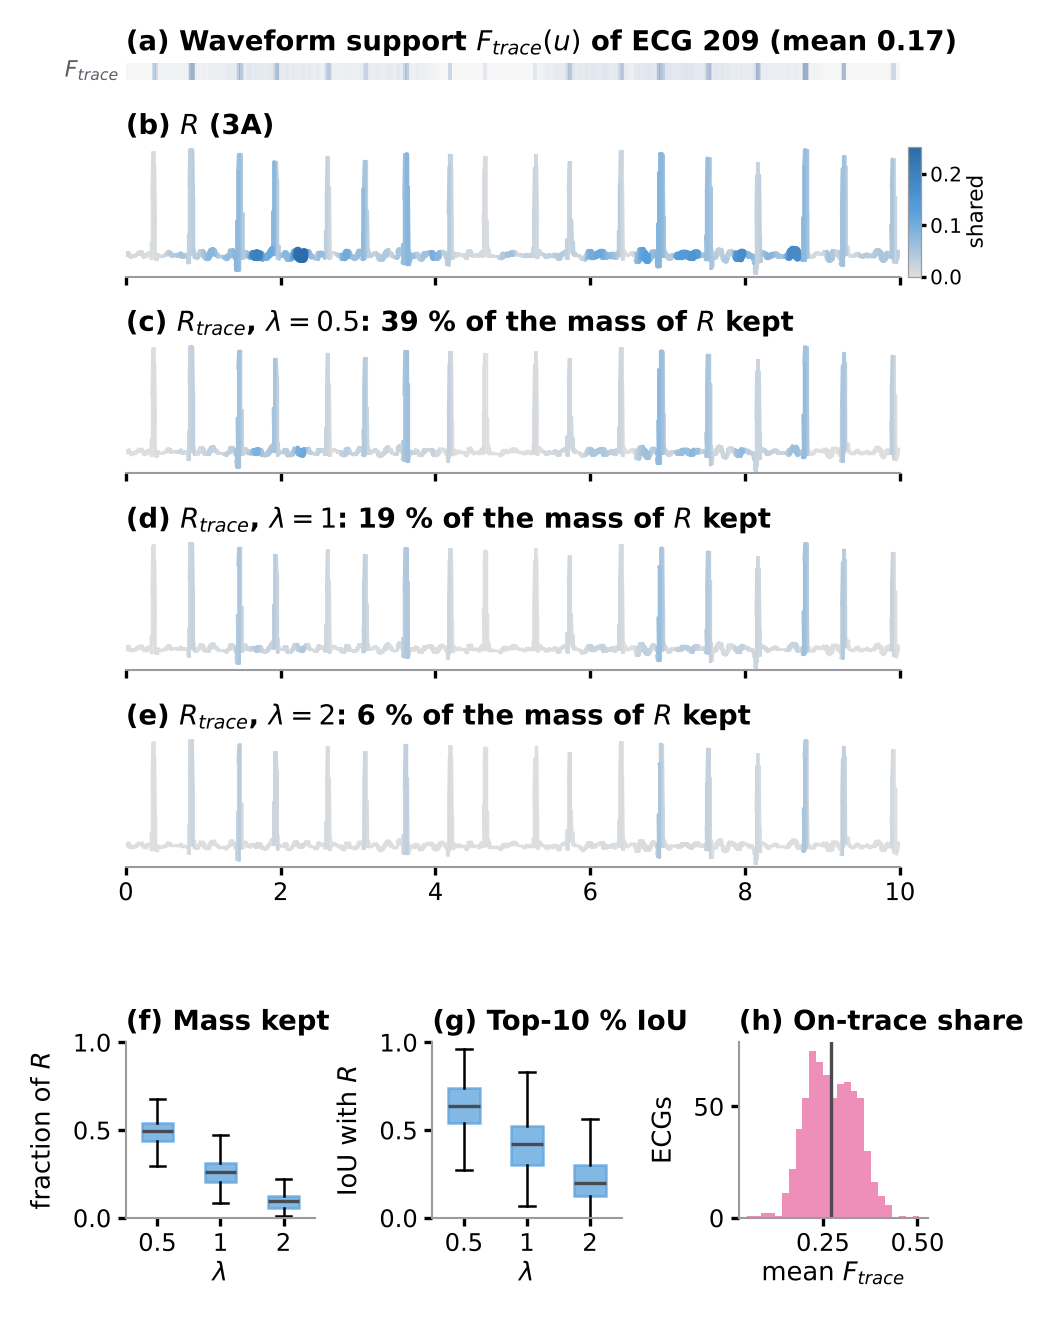

In [8]:
F.fig_module3b(ARCH / 'module3b/module3b_maps.npz', m3b, mask, FIG)
C.fig_module3b_column(ARCH / 'module3b/module3b_maps.npz', m3b, mask, FIG)   # single-column version used in the report
show('col_module3B', 420)